<a href="https://colab.research.google.com/github/manjunadha12/CSA4703-Deep-Learning/blob/main/Lab/Exp29.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Fashion-MNIST subset shape: (15000, 28, 28, 1)

=== Task 1: Training VAE on Fashion-MNIST ===
Epoch 1/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 28s 182ms/step - kl_loss: 4.5259 - recon_loss: 399.2460 - total_loss: 403.7718
Epoch 2/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 19s 163ms/step - kl_loss: 7.7060 - recon_loss: 322.5987 - total_loss: 330.3047
Epoch 3/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 22s 172ms/step - kl_loss: 5.4438 - recon_loss: 304.0867 - total_loss: 309.5305
Epoch 4/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 19s 161ms/step - kl_loss: 4.3518 - recon_loss: 300.1401 - total_loss: 304.4917
Epoch 5/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 20s 173ms/step - kl_loss: 4.0104 - recon_loss: 298.4423 - total_loss: 302.4528
Epoch 6/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 19s 160ms/step - kl_loss: 3.8896 - recon_loss: 297.2203 - total_loss: 301.1099
Epoc

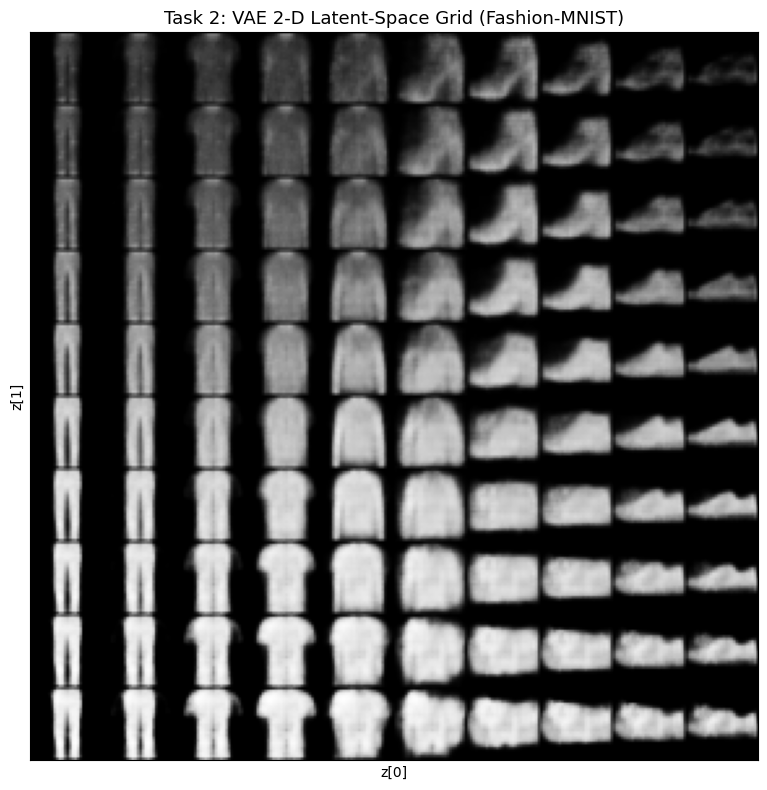


=== Task 4: Training DCGAN on Fashion-MNIST ===
Epoch  1/15 | Generator Loss: 0.7728 | Discriminator Loss: 1.1245


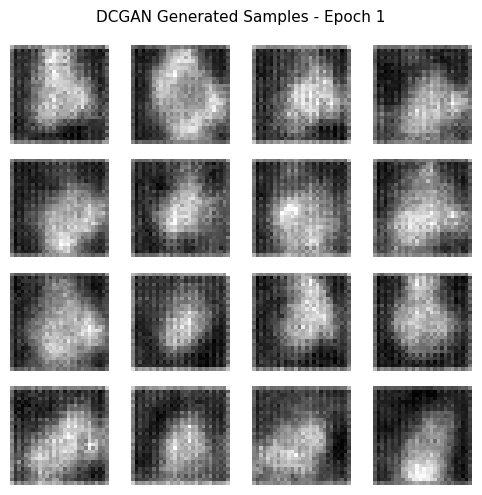

Epoch  2/15 | Generator Loss: 0.7224 | Discriminator Loss: 1.3501
Epoch  3/15 | Generator Loss: 0.7255 | Discriminator Loss: 1.3484
Epoch  4/15 | Generator Loss: 0.7547 | Discriminator Loss: 1.3143
Epoch  5/15 | Generator Loss: 0.7792 | Discriminator Loss: 1.2832


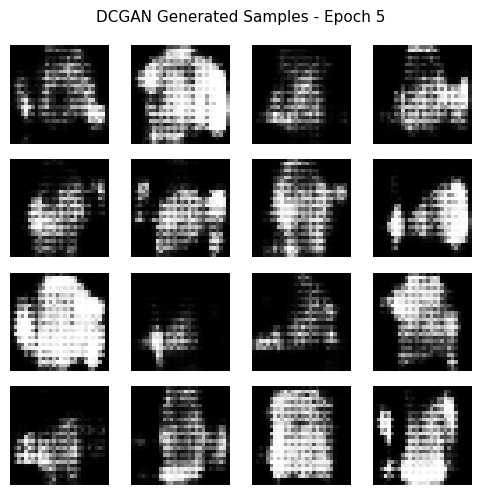

Epoch  6/15 | Generator Loss: 0.8198 | Discriminator Loss: 1.2349
Epoch  7/15 | Generator Loss: 0.8733 | Discriminator Loss: 1.1795
Epoch  8/15 | Generator Loss: 0.9471 | Discriminator Loss: 1.1014
Epoch  9/15 | Generator Loss: 1.0266 | Discriminator Loss: 1.0581
Epoch 10/15 | Generator Loss: 1.0499 | Discriminator Loss: 1.0274


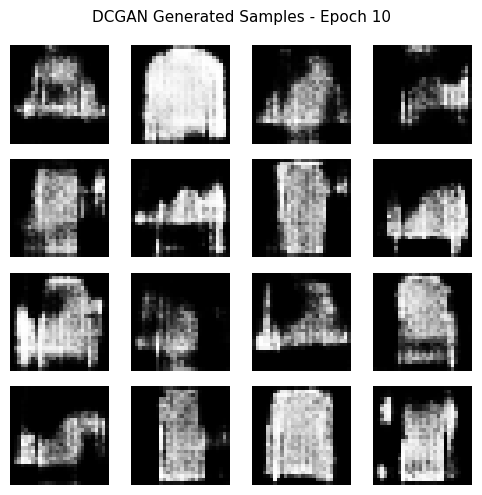

Epoch 11/15 | Generator Loss: 1.1099 | Discriminator Loss: 1.0103
Epoch 12/15 | Generator Loss: 1.0760 | Discriminator Loss: 1.0271
Epoch 13/15 | Generator Loss: 1.1555 | Discriminator Loss: 0.9958
Epoch 14/15 | Generator Loss: 1.0631 | Discriminator Loss: 1.0636
Epoch 15/15 | Generator Loss: 1.0792 | Discriminator Loss: 1.0723


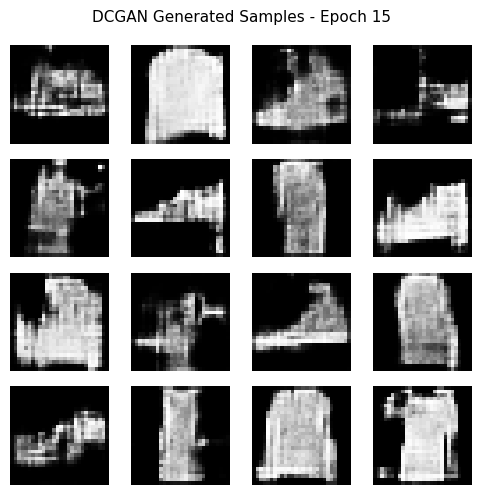

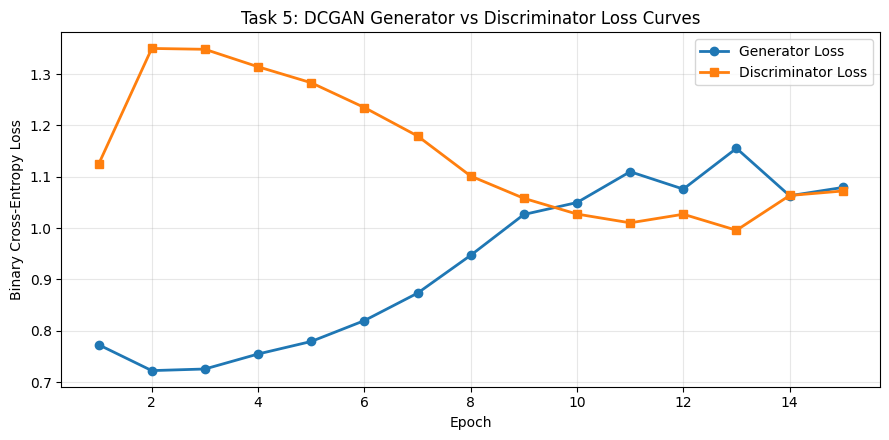

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# ==========================================
# Load Fashion-MNIST Dataset (28x28)
# ==========================================
(X_train_raw, _), _ = keras.datasets.fashion_mnist.load_data()

# Subset of 15,000 images for fast Colab execution (increase to 60,000 if using GPU for sharper results)
X_vae = (X_train_raw[:15000].astype("float32") / 255.0)[..., np.newaxis]       # [0, 1] for VAE
X_gan = ((X_train_raw[:15000].astype("float32") - 127.5) / 127.5)[..., np.newaxis]  # [-1, 1] for DCGAN

print(f"Fashion-MNIST subset shape: {X_vae.shape}\n")

# ==========================================
# Task 1: Build & Train VAE (Encoder, Reparameterisation, Decoder, Recon + KL Loss)
# ==========================================
LATENT_DIM = 2  # 2-D latent space for Task 2 grid visualisation

class Sampling(layers.Layer):
    """Reparameterisation trick: z = z_mean + exp(0.5 * z_log_var) * epsilon."""
    def call(self, inputs):
        z_mean, z_log_var = inputs
        epsilon = tf.random.normal(shape=tf.shape(z_mean))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

# Encoder
enc_inputs = keras.Input(shape=(28, 28, 1))
x = layers.Conv2D(32, 3, strides=2, padding="same", activation="relu")(enc_inputs)
x = layers.Conv2D(64, 3, strides=2, padding="same", activation="relu")(x)
x = layers.Flatten()(x)
x = layers.Dense(32, activation="relu")(x)
z_mean = layers.Dense(LATENT_DIM, name="z_mean")(x)
z_log_var = layers.Dense(LATENT_DIM, name="z_log_var")(x)
z = Sampling()([z_mean, z_log_var])
encoder = keras.Model(enc_inputs, [z_mean, z_log_var, z], name="encoder")

# Decoder
dec_inputs = keras.Input(shape=(LATENT_DIM,))
x = layers.Dense(7 * 7 * 64, activation="relu")(dec_inputs)
x = layers.Reshape((7, 7, 64))(x)
x = layers.Conv2DTranspose(64, 3, strides=2, padding="same", activation="relu")(x)
x = layers.Conv2DTranspose(32, 3, strides=2, padding="same", activation="relu")(x)
dec_outputs = layers.Conv2DTranspose(1, 3, padding="same", activation="sigmoid")(x)
decoder = keras.Model(dec_inputs, dec_outputs, name="decoder")

class VAE(keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.total_loss_tracker = keras.metrics.Mean(name="total_loss")
        self.recon_loss_tracker = keras.metrics.Mean(name="recon_loss")
        self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [self.total_loss_tracker, self.recon_loss_tracker, self.kl_loss_tracker]

    def train_step(self, data):
        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder(data, training=True)
            recon = self.decoder(z, training=True)
            # Binary cross-entropy reconstruction loss summed over pixels
            recon_loss = tf.reduce_mean(
                tf.reduce_sum(keras.losses.binary_crossentropy(data, recon), axis=(1, 2))
            )
            # KL divergence loss
            kl_loss = -0.5 * tf.reduce_mean(
                tf.reduce_sum(1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var), axis=1)
            )
            total_loss = recon_loss + kl_loss

        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))

        self.total_loss_tracker.update_state(total_loss)
        self.recon_loss_tracker.update_state(recon_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        return {
            "total_loss": self.total_loss_tracker.result(),
            "recon_loss": self.recon_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result(),
        }

print("=== Task 1: Training VAE on Fashion-MNIST ===")
vae = VAE(encoder, decoder)
vae.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3))
vae.fit(X_vae, epochs=10, batch_size=128, verbose=1)

# ==========================================
# Task 2: Sample Latent Space & Plot 2-D Latent-Space Grid
# ==========================================
n_grid = 10
digit_size = 28
figure = np.zeros((digit_size * n_grid, digit_size * n_grid))
grid_x = np.linspace(-2.5, 2.5, n_grid)
grid_y = np.linspace(-2.5, 2.5, n_grid)[::-1]

for i, yi in enumerate(grid_y):
    for j, xi in enumerate(grid_x):
        z_sample = np.array([[xi, yi]], dtype=np.float32)
        x_decoded = vae.decoder.predict(z_sample, verbose=0)
        figure[
            i * digit_size : (i + 1) * digit_size,
            j * digit_size : (j + 1) * digit_size,
        ] = x_decoded[0, :, :, 0]

plt.figure(figsize=(8, 8))
plt.imshow(figure, cmap="gray")
plt.title("Task 2: VAE 2-D Latent-Space Grid (Fashion-MNIST)", fontsize=13)
plt.xlabel("z[0]")
plt.ylabel("z[1]")
plt.xticks([])
plt.yticks([])
plt.tight_layout()
plt.show()

# ==========================================
# Task 3: Build DCGAN (Generator & Discriminator)
# ==========================================
NOISE_DIM = 64

def build_generator():
    return keras.Sequential([
        layers.Input(shape=(NOISE_DIM,)),
        layers.Dense(7 * 7 * 128, use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(0.2),
        layers.Reshape((7, 7, 128)),
        layers.Conv2DTranspose(64, 4, strides=2, padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(0.2),
        layers.Conv2DTranspose(1, 4, strides=2, padding="same", use_bias=False, activation="tanh"),
    ], name="generator")

def build_discriminator():
    return keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(64, 4, strides=2, padding="same"),
        layers.LeakyReLU(0.2),
        layers.Dropout(0.3),
        layers.Conv2D(128, 4, strides=2, padding="same"),
        layers.LeakyReLU(0.2),
        layers.Dropout(0.3),
        layers.Flatten(),
        layers.Dense(1),  # Logits
    ], name="discriminator")

generator = build_generator()
discriminator = build_discriminator()

bce = keras.losses.BinaryCrossentropy(from_logits=True)
g_opt = keras.optimizers.Adam(learning_rate=2e-4, beta_1=0.5)
d_opt = keras.optimizers.Adam(learning_rate=2e-4, beta_1=0.5)

@tf.function
def gan_train_step(real_images):
    batch_size = tf.shape(real_images)[0]
    noise = tf.random.normal([batch_size, NOISE_DIM])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        fake_images = generator(noise, training=True)
        real_logits = discriminator(real_images, training=True)
        fake_logits = discriminator(fake_images, training=True)

        d_loss_real = bce(tf.ones_like(real_logits), real_logits)
        d_loss_fake = bce(tf.zeros_like(fake_logits), fake_logits)
        d_loss = d_loss_real + d_loss_fake
        g_loss = bce(tf.ones_like(fake_logits), fake_logits)

    g_grads = gen_tape.gradient(g_loss, generator.trainable_variables)
    d_grads = disc_tape.gradient(d_loss, discriminator.trainable_variables)
    g_opt.apply_gradients(zip(g_grads, generator.trainable_variables))
    d_opt.apply_gradients(zip(d_grads, discriminator.trainable_variables))
    return g_loss, d_loss

# ==========================================
# Task 4: Train DCGAN & Save Generated Images Every Few Epochs
# ==========================================
os.makedirs("gan_samples", exist_ok=True)
fixed_noise = tf.random.normal([16, NOISE_DIM], seed=42)
gan_dataset = tf.data.Dataset.from_tensor_slices(X_gan).shuffle(10000).batch(128)

GAN_EPOCHS = 15
g_losses, d_losses = [], []

def save_and_show_gan_grid(epoch):
    preds = generator(fixed_noise, training=False).numpy()
    preds = (preds + 1.0) / 2.0  # Rescale [-1, 1] -> [0, 1]
    fig, axes = plt.subplots(4, 4, figsize=(5, 5))
    for i, ax in enumerate(axes.ravel()):
        ax.imshow(preds[i, :, :, 0], cmap="gray")
        ax.axis("off")
    plt.suptitle(f"DCGAN Generated Samples - Epoch {epoch}", fontsize=11)
    plt.tight_layout()
    plt.savefig(f"gan_samples/epoch_{epoch:02d}.png")
    plt.show()

print("\n=== Task 4: Training DCGAN on Fashion-MNIST ===")
for epoch in range(1, GAN_EPOCHS + 1):
    ep_g, ep_d = [], []
    for batch in gan_dataset:
        gl, dl = gan_train_step(batch)
        ep_g.append(float(gl))
        ep_d.append(float(dl))

    avg_g, avg_d = np.mean(ep_g), np.mean(ep_d)
    g_losses.append(avg_g)
    d_losses.append(avg_d)
    print(f"Epoch {epoch:2d}/{GAN_EPOCHS} | Generator Loss: {avg_g:.4f} | Discriminator Loss: {avg_d:.4f}")

    if epoch in [1, 5, 10, 15]:
        save_and_show_gan_grid(epoch)

# ==========================================
# Task 5: Plot Generator & Discriminator Loss Curves
# ==========================================
plt.figure(figsize=(9, 4.5))
plt.plot(range(1, GAN_EPOCHS + 1), g_losses, marker="o", linewidth=2, label="Generator Loss")
plt.plot(range(1, GAN_EPOCHS + 1), d_losses, marker="s", linewidth=2, label="Discriminator Loss")
plt.title("Task 5: DCGAN Generator vs Discriminator Loss Curves")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()